In [2]:
#EDA ideas borrowed from https://www.kaggle.com/code/egorandreasyan/baseline-eda-stellar-class
import os
import math
from pathlib import Path
import pickle
import random
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    log_loss,
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    f1_score,
    precision_score,
    roc_curve
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.cluster import KMeans
from itertools import combinations
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    HistGradientBoostingClassifier, 
    RandomForestClassifier
)
from sklearn.pipeline import Pipeline
# from catboost import CatBoostClassifier
# from xgboost import XGBClassifier
# import lightgbm as lgb
# from lightgbm import LGBMClassifier
# from scipy.optimize import differential_evolution, minimize
# from scipy.special import softmax
from itertools import combinations
from collections import Counter
import seaborn as sns
from tqdm import tqdm
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("data/train.csv")
print("Number of rows:", df.shape[0])
print("Number of unique objects in 'class' column:", df['class'].unique())
print(df.columns)

Number of rows: 577347
Number of unique objects in 'class' column: <StringArray>
['GALAXY', 'QSO', 'STAR']
Length: 3, dtype: str
Index(['id', 'alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift',
       'spectral_type', 'galaxy_population', 'class'],
      dtype='str')


In [5]:
for obj in ['spectral_type','galaxy_population','class']:
    print(f"Unique objects in '{obj}' column:", df[obj].unique())

Unique objects in 'spectral_type' column: <StringArray>
['M', 'O/B', 'G/K', 'A/F']
Length: 4, dtype: str
Unique objects in 'galaxy_population' column: <StringArray>
['Red_Sequence', 'Blue_Cloud']
Length: 2, dtype: str
Unique objects in 'class' column: <StringArray>
['GALAXY', 'QSO', 'STAR']
Length: 3, dtype: str


In [6]:
def plot_smart_pie_charts(df: pd.DataFrame) -> list:
    sns.set_theme(style="whitegrid", palette="pastel")
    obj_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    n_features = len(obj_cols)
    if n_features == 0:
        return
    if n_features <= 3:
        cols_in_row = n_features
    elif n_features == 4:
        cols_in_row = 2
    else:
        cols_in_row = 3 if n_features < 10 else 4
    rows = math.ceil(n_features / cols_in_row)
    fig, axes = plt.subplots(rows, cols_in_row,
                             figsize=(cols_in_row * 5, rows * 5),
                             squeeze=False)
    axes = axes.flatten()
    for i, col in enumerate(obj_cols):
        ax = axes[i]
        counts = df[col].value_counts()
        limit = 8
        if len(counts) > limit:
            top = counts.iloc[:limit-1]
            others = pd.Series({'Others': counts.iloc[limit-1:].sum()})
            plot_data = pd.concat([top, others])
        else:
            plot_data = counts
        plot_data = plot_data.sort_index(ascending=False)
        ax.pie(plot_data,
               labels=plot_data.index,
               autopct='%1.1f%%',
               startangle=140,
               pctdistance=0.85,
               colors=sns.color_palette("hls", len(plot_data)),
               wedgeprops={'width': 0.5, 'edgecolor': 'w', 'linewidth': 2})
        ax.set_title(f"{col}", fontsize=14, fontweight='bold', pad=20)
    for j in range(n_features, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()
    return obj_cols




/tmp/ipykernel_5724/1977032912.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


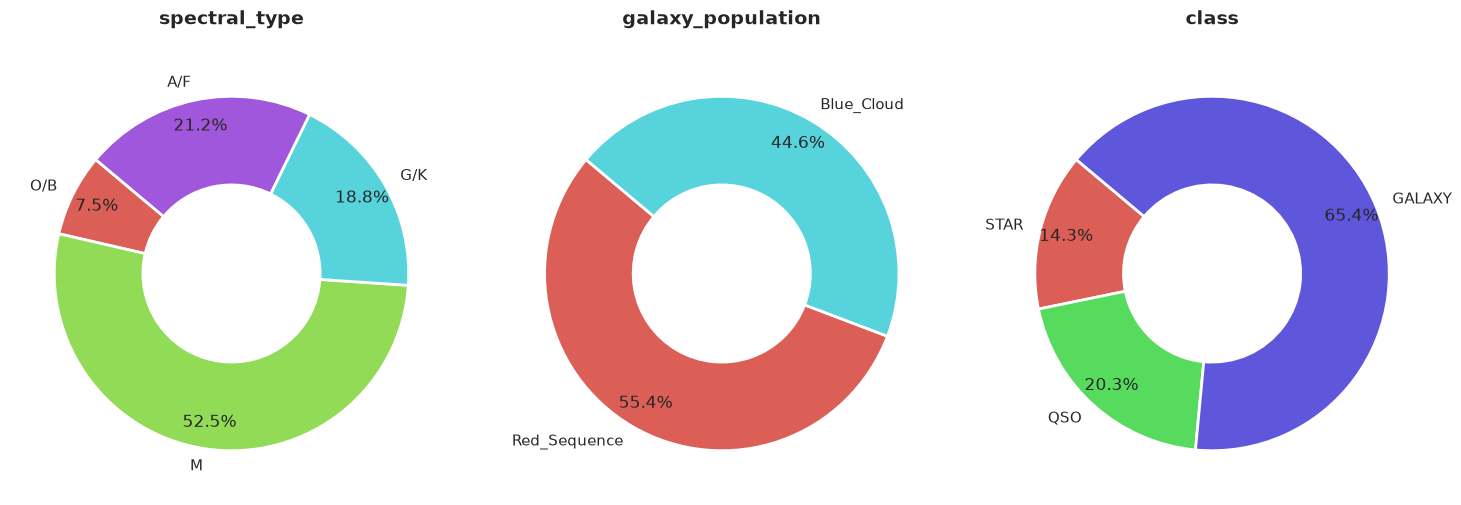

In [7]:
cat_cols = plot_smart_pie_charts(df)

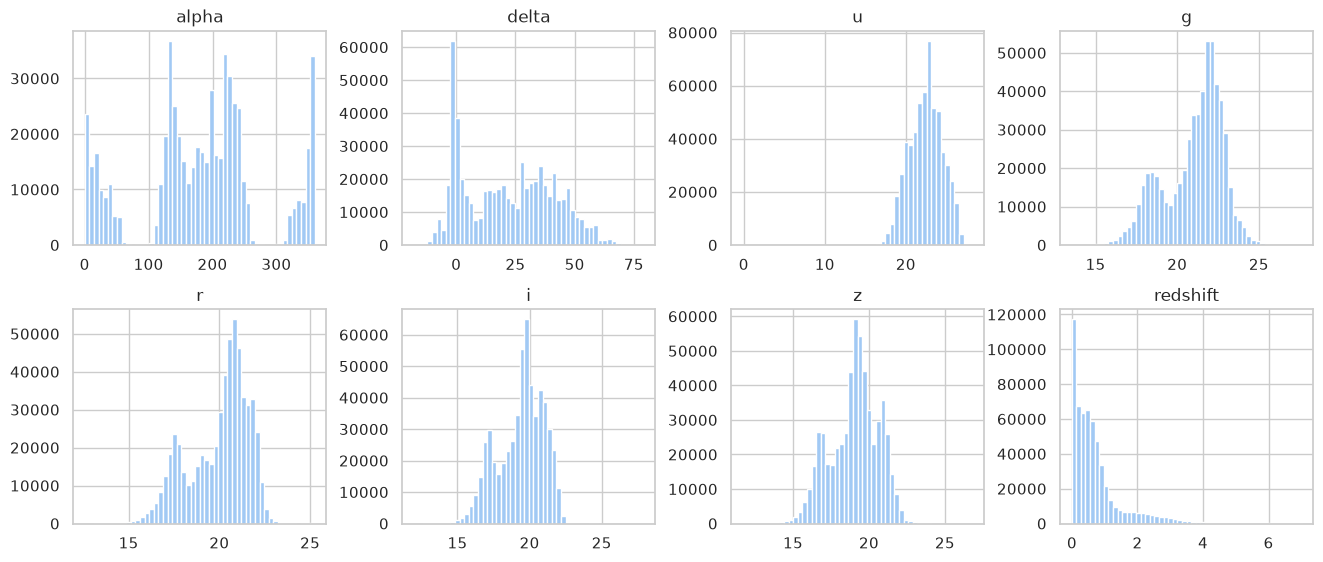

In [8]:
data = df.copy()
data = data.drop(columns=['id'])
n = data.select_dtypes('number').shape[1]
data.hist(figsize=(min(4, n) * 4, ((n + 3) // 4) * 3.2), bins=50, layout=(-1, 4));

Classification: GALAXY


/tmp/ipykernel_5724/1977032912.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


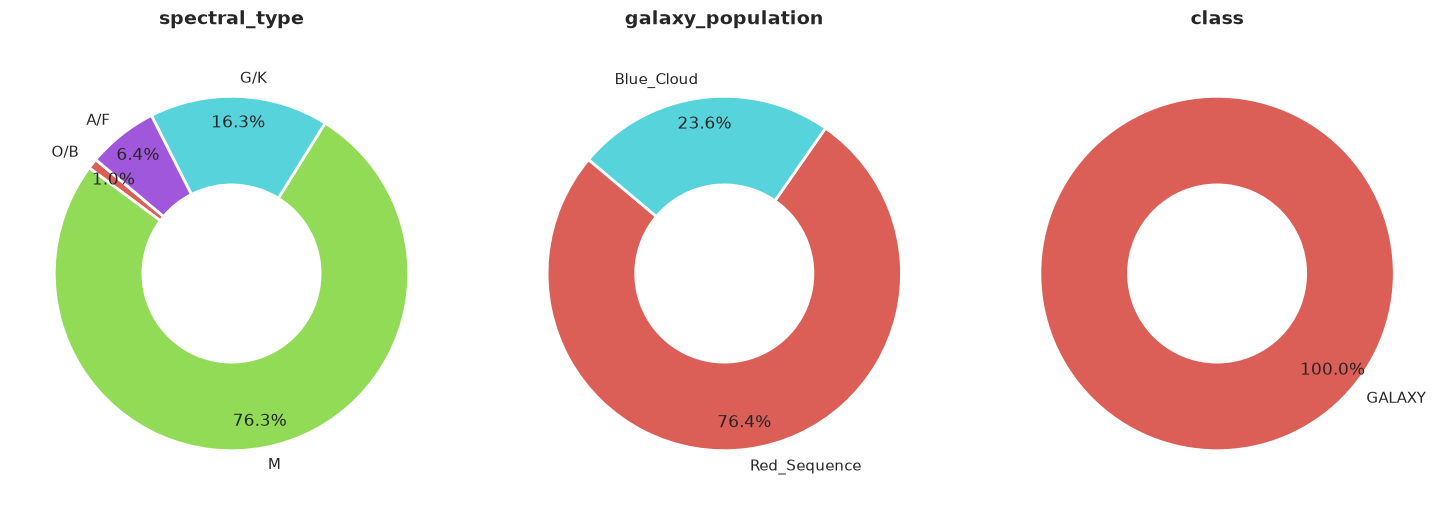

Classification: QSO


/tmp/ipykernel_5724/1977032912.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


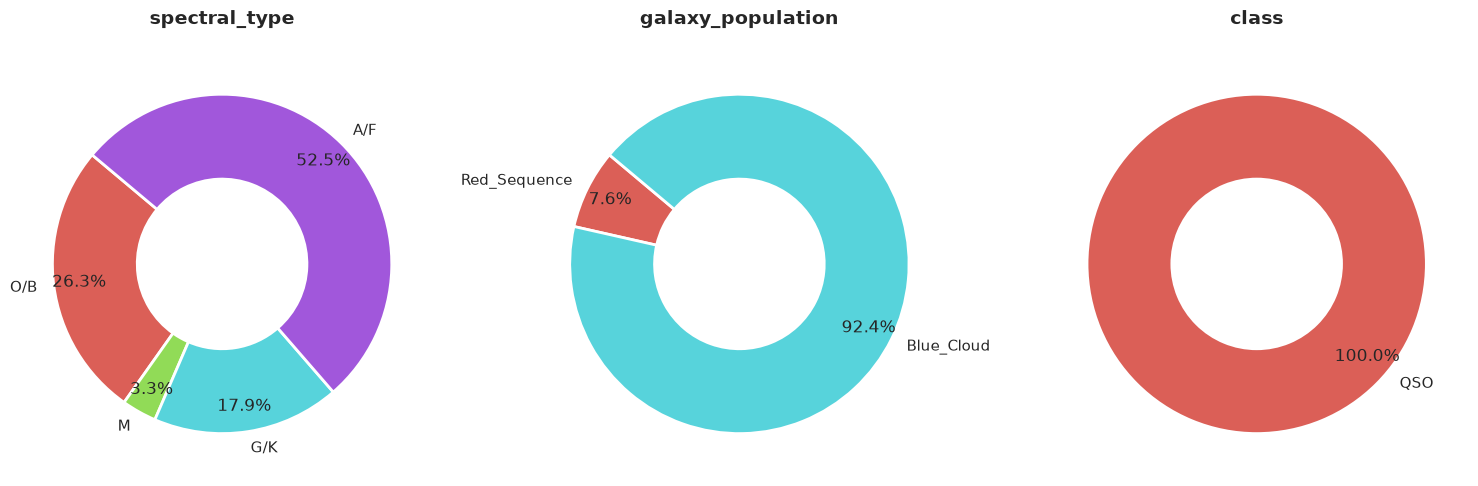

Classification: STAR


/tmp/ipykernel_5724/1977032912.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


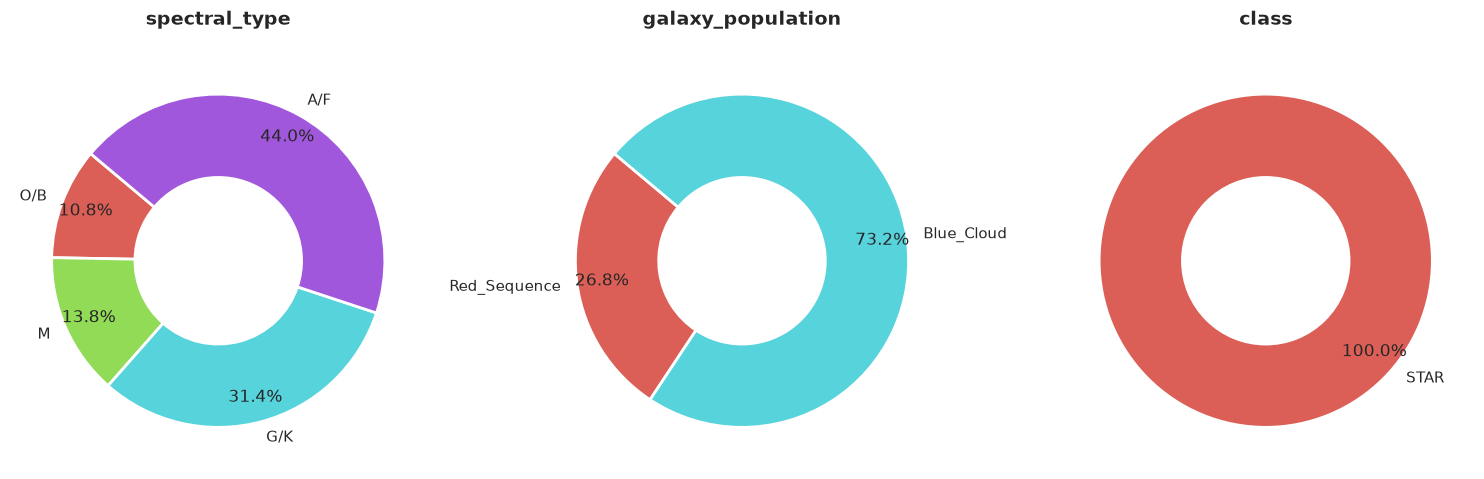

In [9]:
#now, do this for each class type
#categoricals
for classification in df['class'].unique():
    df_filtered = df[df['class'] == classification].copy()
    df_filtered = df_filtered.drop(columns=['id'])
    print(f'Classification: {classification}')
    plot_smart_pie_charts(df_filtered)


/usr/local/python/3.12.1/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


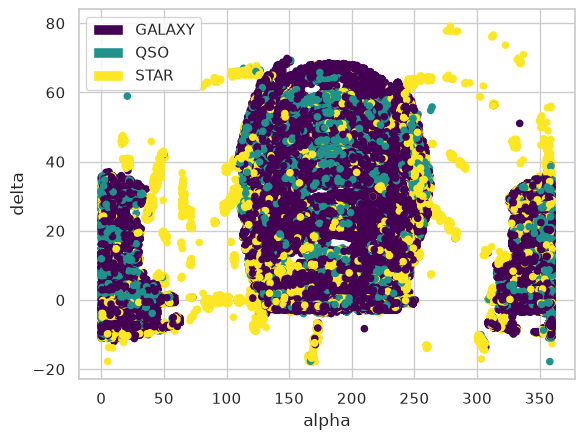

In [ ]:
# a 2D scatterplot showing "longitude" and "latitude" vs class
df.plot.scatter(x='alpha', y='delta', c='class', cmap='viridis')

plt.show()

In [ ]:
# calculating the correlation of each numerical variable with the 'class' column

# defining a correlation ratio function

###
# Note: correlation between numeric and categorical has no meaning, ignore
###

def correlation_ratio(categories, measurements):
    """Calculates the correlation ratio (Eta) between a categorical and a numeric variable."""
    categories = np.array(categories)
    measurements = np.array(measurements)

    if len(categories) == 0 or len(np.unique(categories)) <= 1:
        print("error")
        return 0.0

    # calculate overall mean and group-specific metrics
    fcat = pd.Categorical(categories)
    cat_num = fcat.codes
    y_mean = np.mean(measurements)

    # group counts and means
    lnum = np.bincount(cat_num)
    g_means = np.bincount(cat_num, weights=measurements) / lnum

    # calculate sum of squares, both total and within each group
    ss_total = np.sum((measurements - y_mean) ** 2)
    ss_explained = np.sum(lnum * (g_means - y_mean) ** 2)

    if ss_total == 0:
        return 0.0

    return np.sqrt(ss_explained / ss_total)


new_df = df.copy()
new_df = new_df.drop(columns=['id'])
# targeting the 'class' category column
TARGET_CAT = "class"

# pick out all columns with numeric data
results = {}
numeric_cols = new_df.select_dtypes(include=[np.number]).columns
print(numeric_cols)

for num_col in numeric_cols:
    score = correlation_ratio(new_df[TARGET_CAT], new_df[num_col])
    results[num_col] = score

# Convert to a DataFrame and sort by strength
corr_df = pd.DataFrame(list(results.items()), columns=["Numeric_Column", "Correlation_Ratio"])
corr_df = corr_df.sort_values(by="Correlation_Ratio", ascending=False).reset_index(
    drop=True
)

print("Correlation with", TARGET_CAT)
print(corr_df)

Index(['alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift'], dtype='str')
Correlation with class
  Numeric_Column  Correlation_Ratio
0       redshift           0.741657
1              z           0.497368
2              i           0.446316
3              u           0.388477
4              r           0.334917
5              g           0.323485
6          delta           0.108094
7          alpha           0.046707


In [ ]:
# convert alpha and delta to radians, then use cos() and sin() to map from the 2D plane to a 3D sphere

alpha_rad = np.radians(df['alpha'])
delta_rad = np.radians(df['delta'])

df['X_loc'] = np.cos(delta_rad) * np.cos(alpha_rad)
df['Y_loc'] = np.cos(delta_rad) * np.sin(alpha_rad)
df['Z_loc'] = np.sin(delta_rad)


Classification: GALAXY
Classification: QSO
Classification: STAR


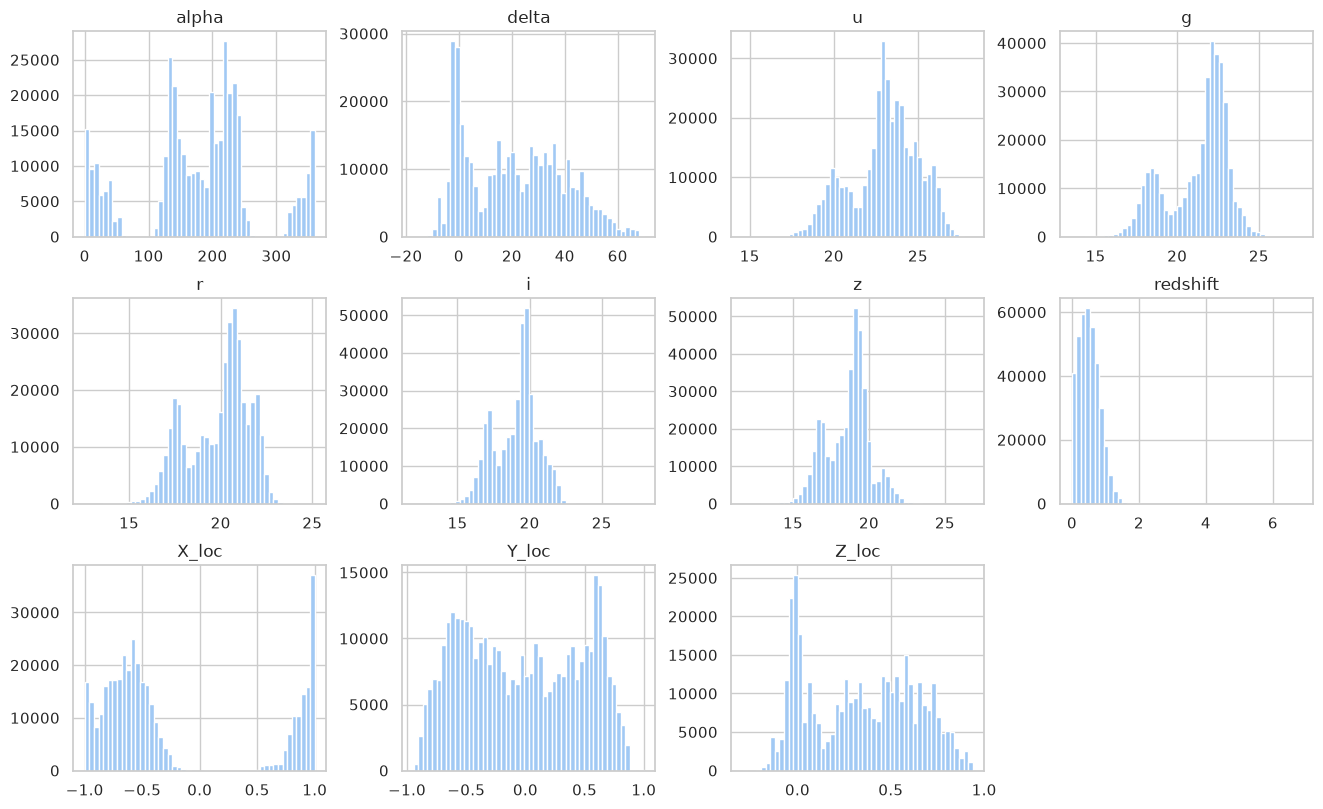

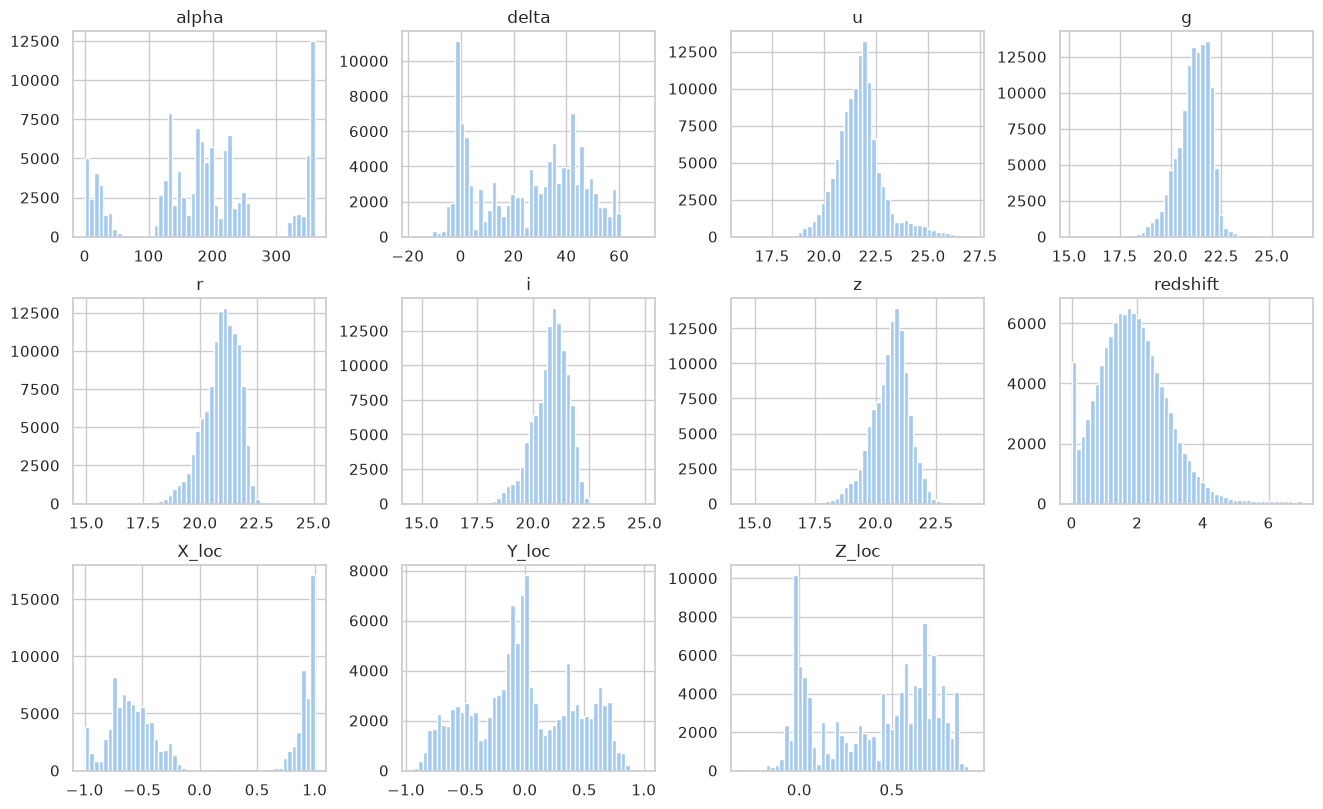

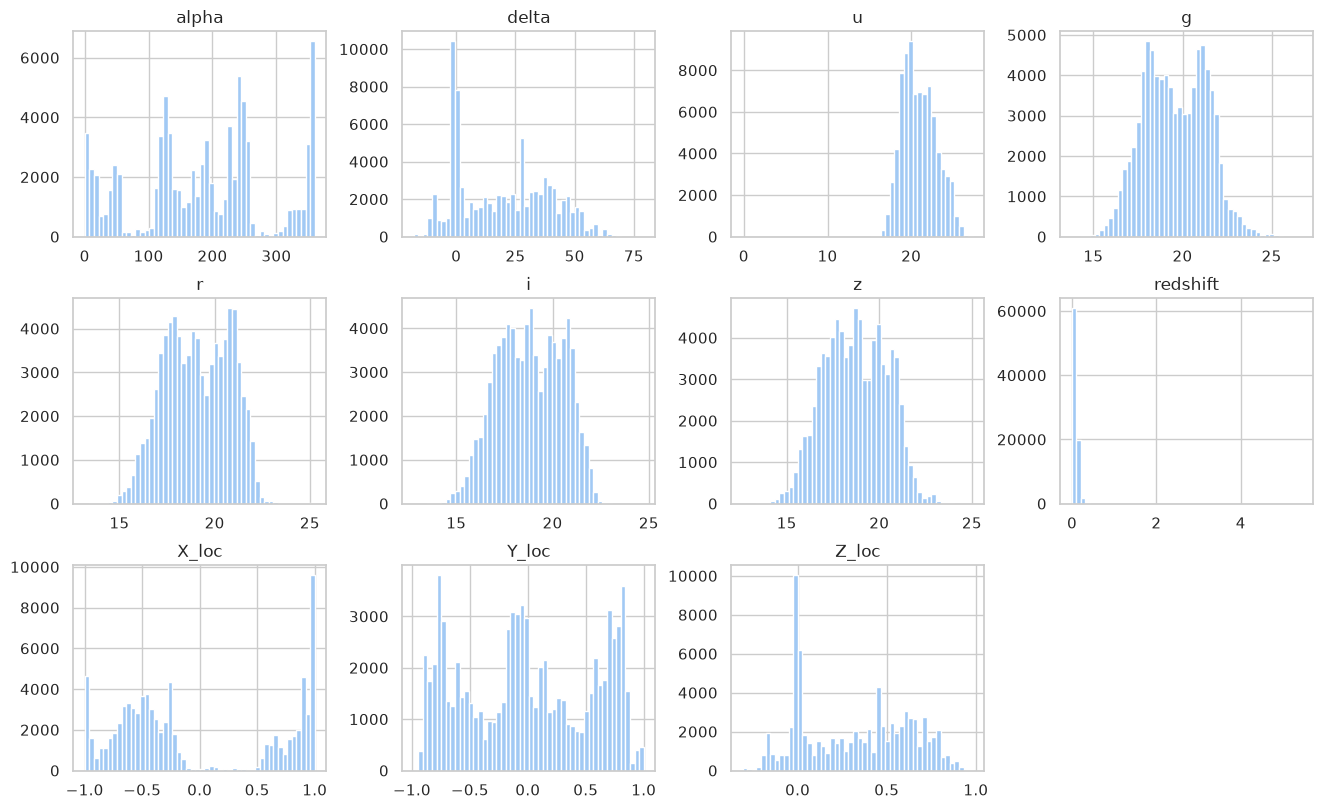

In [22]:
#and for numerics
for classification in df['class'].unique():
    df_filtered = df[df['class'] == classification].copy()
    df_filtered = df_filtered.drop(columns=['id'])
    print(f'Classification: {classification}')
    # plot_smart_pie_charts(df_filtered)
    data = df_filtered
    n = data.select_dtypes('number').shape[1]
    data.hist(figsize=(min(4, n) * 4, ((n + 3) // 4) * 3.2), bins=50, layout=(-1, 4));


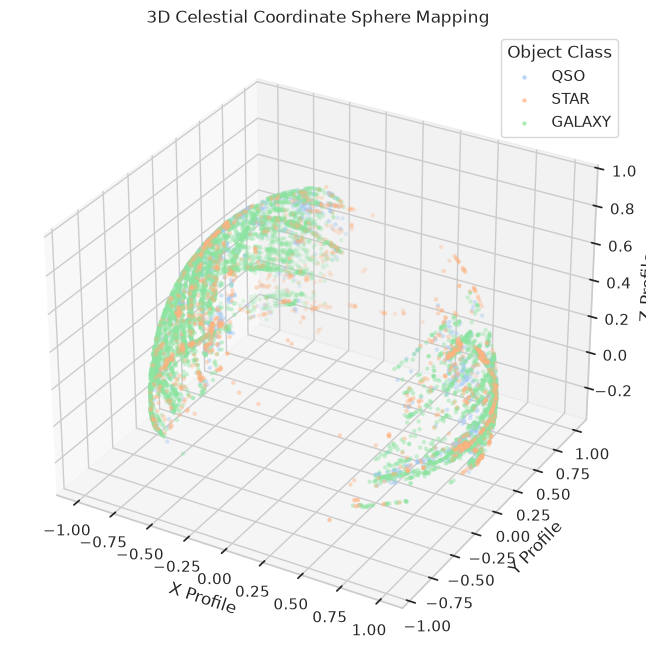

In [23]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Sample down since the data set is a bit too large
sampled_df = df.sample(n=min(10000, len(df)), random_state=42)

for class_type in sampled_df['class'].unique():
    subset = sampled_df[sampled_df['class'] == class_type]
    ax.scatter(subset['X_loc'], subset['Y_loc'], subset['Z_loc'], label=class_type, s=5, alpha=0.6)

ax.set_title("3D Celestial Coordinate Sphere Mapping")
ax.set_xlabel("X Profile")
ax.set_ylabel("Y Profile")
ax.set_zlabel("Z Profile")
ax.legend(title="Object Class")
plt.show()